(p4-theory-decision-trees-ensemble)=
# P4 이론: 결정 트리와 앙상블 학습

**감사의 글**

오렐리앙 제롱<font size='2'>Aurélien Géron</font>의 [Hands-On Machine Learning with Scikit-Learn and PyTorch (O'Reilly, 2025)](https://github.com/ageron/handson-mlp)에 사용된 코드를 참고한 강의노트이다. 보다 심화된 이해를 위해 책 원본을 읽을 것을 강력하게 권장한다. 자료를 공개한 오렐리앙 제롱과 일부 그림 자료를 제공해 준 한빛아카데미에게 진심어린 감사를 전한다.

**주요 내용**

**결정 트리가 어떤 기준으로 데이터를 분할하는지**, **여러 트리를 왜 결합하는지**, 그리고 **어떤 결과를 보고 모델의 일반화 성능을 판단할지** 이해한다.

> **결정 트리의 분할 → 트리 깊이와 과대적합 → 배깅과 OOB → 랜덤 포레스트 분류·회귀 → 그레이디언트 부스팅 회귀·분류 → XGBoost → 모델 판단**

학습을 마치면 다음을 설명할 수 있어야 한다.

- 결정 트리의 노드, 분할 조건, 잎 노드, 불순도와 예측 확률을 설명한다.
- 깊이 2와 3의 트리 구조 및 결정 경계를 비교하고, 과대적합과 규제를 연결한다.
- 배깅의 부트스트랩, OOB 평가, 트리별 특성 선택과 랜덤 포레스트의 노드별 특성 선택을 구분한다.
- 랜덤 포레스트가 분류와 회귀에서 여러 트리의 결과를 결합하는 방식을 설명한다.
- 부스팅의 순차적 학습이 회귀의 잔차 및 분류의 손실 감소와 어떻게 연결되는지 설명한다.
- 훈련·검증·테스트 성능을 근거로 모델을 선택할 때 지켜야 할 원칙을 판단한다.
- XGBoost의 분류·회귀 모델을 살펴보고, 기존 그레이디언트 부스팅과 공통점·차이를 설명한다.

## 1단계: 결정 트리는 어떻게 분류하는가?

**결정 트리**(decision tree)는 입력 특성에 대한 질문을 반복하여 데이터를 여러 영역으로 나누는 모델이다. P4 실습에서는 붓꽃의 **꽃잎 길이**와 **꽃잎 너비** 두 특성으로 세 품종(setosa, versicolor, virginica)을 분류한다.

결정 트리는 분류뿐 아니라 회귀에도 사용할 수 있다. 여기서는 먼저 분류 트리의 구조부터 이해한다.

### 붓꽃 데이터셋 소개

**붓꽃 데이터셋**(Iris dataset)은 꽃받침과 꽃잎의 크기를 이용하여 붓꽃의 품종을 구분하는 대표적인 **다중 클래스 분류**(multiclass classification) 데이터다.

| 구분 | 내용 |
|---|---|
| 샘플 수 | 150개(각 품종 50개씩) |
| 클래스 | setosa, versicolor, virginica (3개) |
| 원래 특성 | 꽃받침 길이·너비, 꽃잎 길이·너비 (4개) |
| P4 실습에서 사용할 특성 | **꽃잎 길이**(petal length), **꽃잎 너비**(petal width) (2개) |

두 특성만 사용하면 **결정 경계를 평면에 그릴 수 있어** 트리가 분할을 반복하는 원리를 쉽게 관찰할 수 있다. 여기서는 구조 학습을 위해 150개 샘플로 트리를 훈련하고 시각화한다. 따라서 아래의 **훈련 정확도는 새로운 데이터에서의 일반화 성능을 뜻하지 않는다.**

### 루트 노드, 분할 조건, 잎 노드

트리를 위에서부터 따라 내려가면 예측이 이루어진다.

- **루트 노드**(root node): 모든 훈련 샘플에서 예측이 시작되는 노드다. 깊이는 `0`이다.
- **내부 노드**(internal node): 예를 들어 `petal length (cm) <= 2.45`처럼 하나의 특성과 임곗값으로 샘플을 두 그룹으로 나눈다.
- **잎 노드**(leaf node): 더 이상 분할하지 않는 노드로, 최종 예측 클래스와 클래스별 비율이 결정된다.

scikit-learn의 `plot_tree()`에는 일반적으로 `gini`(불순도), `samples`(노드의 훈련 샘플 수), `value`(클래스별 구성, scikit-learn 버전에 따라 개수 또는 비율로 표시될 수 있음), `class`(예측 클래스)가 표시된다.

**중요:** `max_depth`는 학습 전에 정하는 **하이퍼파라미터**(hyperparameter)이고, 실제 분할에 쓰이는 특성과 임곗값은 훈련 데이터에서 결정된다.

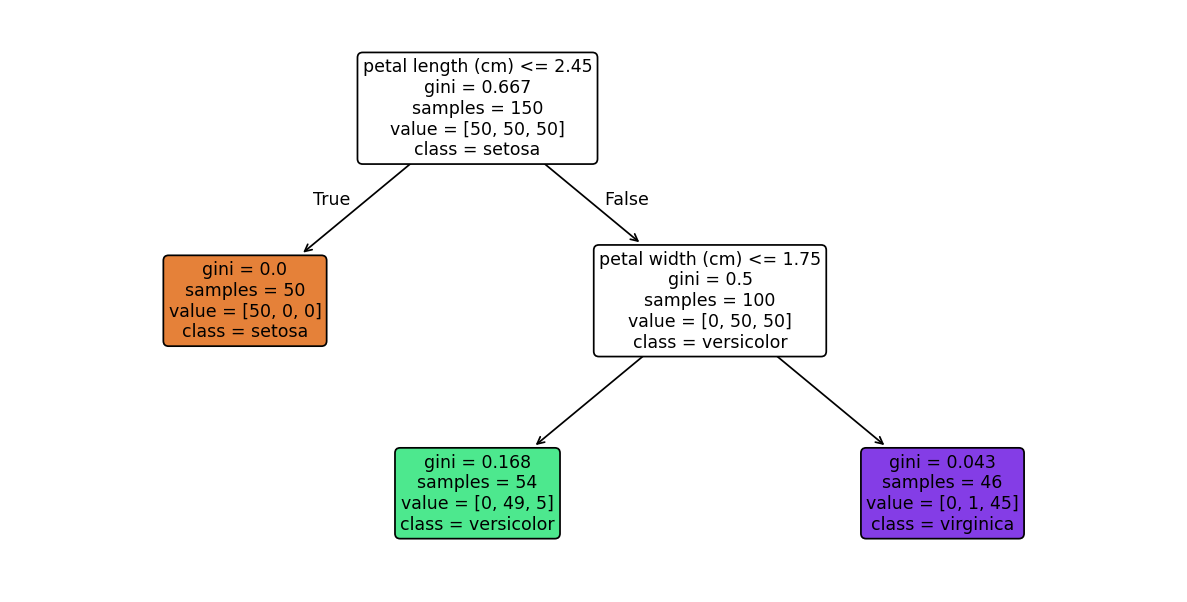

이 그림은 실습의 `DecisionTreeClassifier(max_depth=2, random_state=42)`로 훈련한 트리다. 첫 조건에서 setosa가 다른 품종과 구분되고, 다음 분할에서 versicolor와 virginica를 추가로 구분하는 과정을 확인해 보자.

### 지니 불순도는 무엇을 측정하는가?

한 노드에 여러 클래스가 섞여 있으면 어떤 클래스로 분류할지 불확실하다. 이러한 섞임의 정도를 **지니 불순도**(Gini impurity)로 나타낼 수 있다.

$$ G = 1 - \sum_{k=1}^{K} p_k^2 $$

여기서 $p_k$는 해당 노드의 샘플 중 클래스 $k$가 차지하는 비율이고, $K$는 클래스 수다.

- 한 클래스가 노드의 모든 샘플을 차지하면 $G=0$이다. 즉, 완전히 순수한 노드다.
- 두 클래스의 비율이 각각 50%이면 $G=1-(0.5^2+0.5^2)=0.5$다.
- 불순도가 크다는 것은 한 노드에 여러 클래스가 많이 섞여 있다는 뜻이다.

지니 불순도는 **분류 모델이 분할 규칙을 학습할 때 사용하는 기준**이다. P2에서 배운 정확도·정밀도·재현율처럼 검증 성능을 보고하는 지표와 역할이 다르다.

**실제 트리의 다른 노드에서 계산해 보기**

P4 실습의 `max_depth=2` 결정 트리에서 **가장 오른쪽 잎 노드**에는 총 46개 샘플이 들어 있다. 품종별로 세면 setosa 0개, versicolor 1개, virginica 45개다. 이 노드는 앞의 '두 클래스가 반반인 예'와 달리 한 클래스가 대부분을 차지한다.

$$ G = 1 - \left(\frac{0}{46}\right)^2 - \left(\frac{1}{46}\right)^2 - \left(\frac{45}{46}\right)^2 \approx 0.043 $$

이 값은 0에 가까우므로 **매우 순수한 노드**라고 해석할 수 있다. 실습에서는 이 노드의 실제 클래스 개수를 세고 `tree_.impurity` 값과 비교한다. 반면 부모 노드(versicolor 50개, virginica 50개)의 지니 불순도는 `0.5`다.

### 어떤 분할이 좋은 분할일까?

결정 트리는 한 노드를 두 자식 노드로 나눌 때, **분할 후의 불순도가 작아지는 조건**을 선택한다. 단, 작은 노드 하나만 순수해지는 것은 충분하지 않다. 두 자식 노드에 포함된 샘플 수를 고려해야 한다.

$$ J = \frac{m_{\mathrm{left}}}{m}G_{\mathrm{left}} + \frac{m_{\mathrm{right}}}{m}G_{\mathrm{right}} $$

- $m$: 부모 노드의 샘플 수
- $m_{\mathrm{left}}$, $m_{\mathrm{right}}$: 분할 후 두 자식 노드의 샘플 수
- $G_{\mathrm{left}}$, $G_{\mathrm{right}}$: 두 자식 노드의 지니 불순도

이 값을 작게 만드는 특성과 임곗값을 찾는 방식이 분류 결정 트리의 기본 원리다. scikit-learn의 결정 트리는 **CART**(Classification and Regression Trees) 알고리즘을 사용하며, 각 노드에서 현재 가장 좋은 분할을 선택하는 **탐욕적**(greedy) 방식을 따른다. 따라서 트리 전체에서 언제나 최적인 구조를 보장하지는 않는다.

`DecisionTreeClassifier`는 기본적으로 지니 불순도(`criterion="gini"`)를 사용하며, 설정을 바꾸면 엔트로피 등의 기준도 사용할 수 있다.

### 깊이 2와 깊이 3은 무엇이 다른가?

P4 실습은 같은 붓꽃 데이터로 `max_depth=2`와 `max_depth=3`을 비교한다.

- `max_depth=2`: 루트에서 잎까지 **최대 2번**의 분할을 거칠 수 있다.
- `max_depth=3`: 필요한 가지에 한해 **한 번 더** 분할할 수 있다.

두 모델을 같은 데이터로 훈련하면 다음과 같이 나타난다.

| 비교 항목 | `max_depth=2` | `max_depth=3` |
|---|---:|---:|
| 실제 트리 깊이 | 2 | 3 |
| 잎 노드 수 | 3 | 5 |
| 붓꽃 훈련 정확도 | 0.960 | 0.973 |

깊이가 더 큰 트리는 더 세밀한 규칙을 만들 **수 있지만**, 모든 가지가 반드시 최대 깊이까지 자라지는 않는다. 또한 **훈련 정확도가 더 높다는 사실만으로 새로운 데이터에도 더 좋은 모델이라고 판단할 수 없다.**

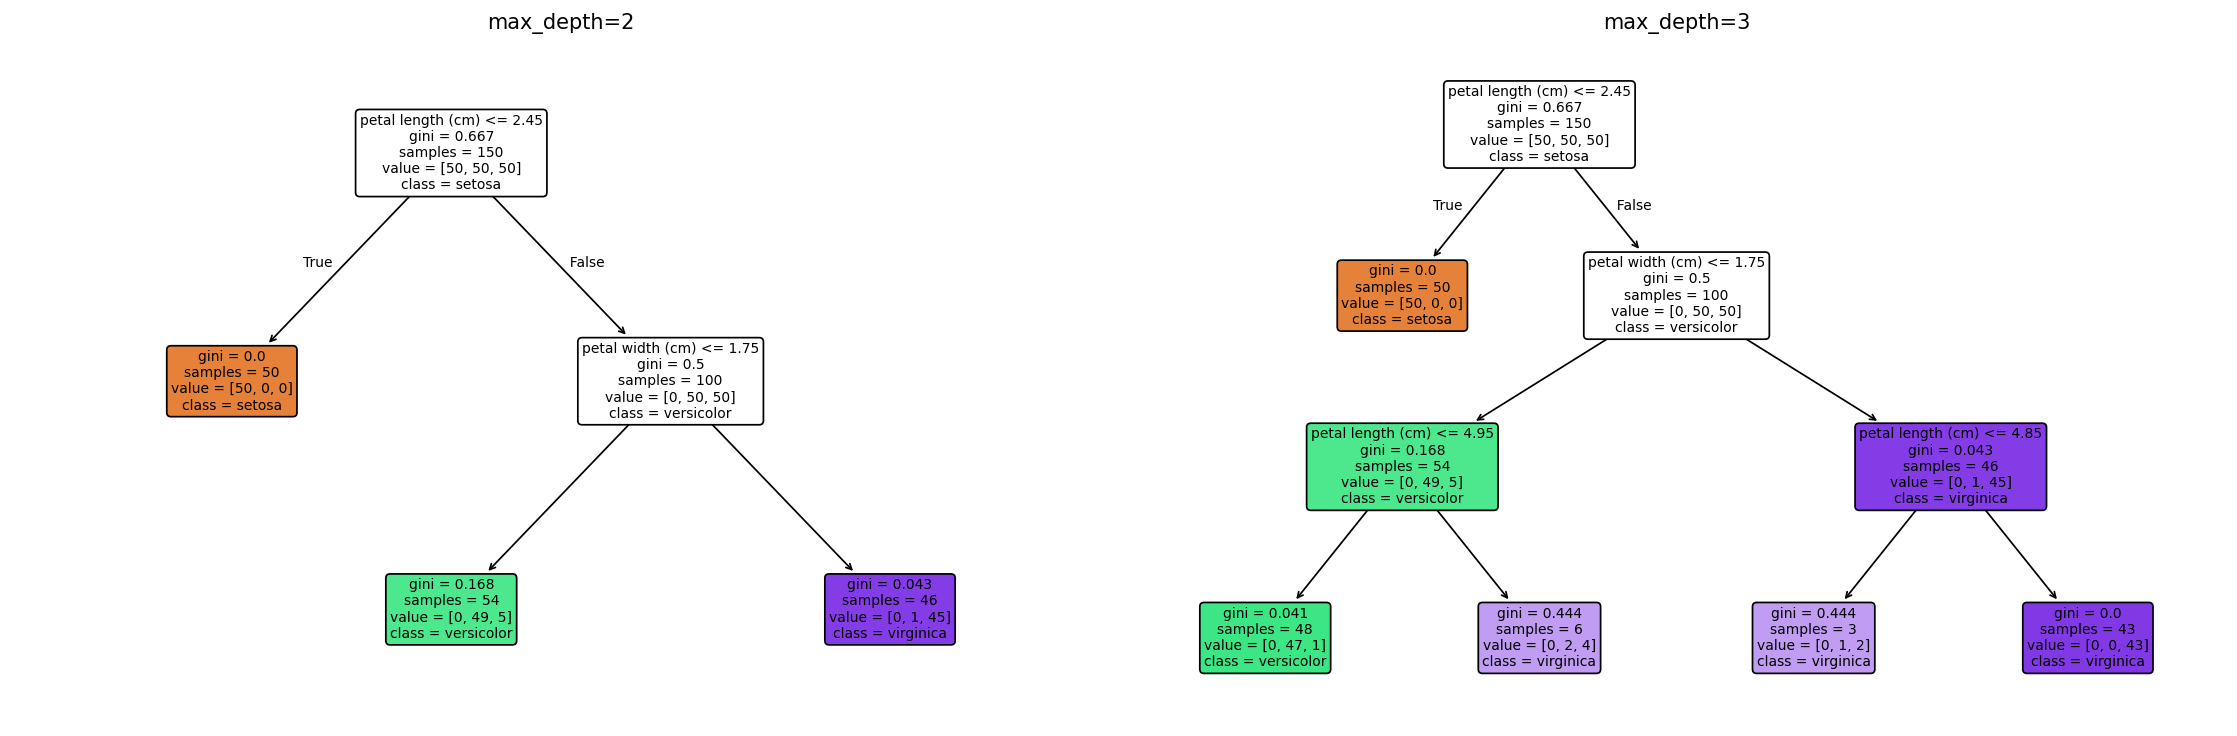

### 예측 확률은 어떻게 만들어질까?

새 샘플을 넣으면 해당 샘플은 분할 규칙을 따라 특정 잎 노드에 도착한다. **분류 결정 트리의 예측 확률**(predicted probability)은 일반적으로 그 잎에 있는 훈련 샘플의 클래스별 비율로 계산된다.

예를 들어 실습의 꽃잎 길이 `5.0`, 너비 `1.5`인 샘플에 대해 깊이 2 트리는 다음 확률을 출력한다.

| 품종 | 예측 확률 |
|---|---:|
| setosa | 0.000 |
| versicolor | 0.907 |
| virginica | 0.093 |

따라서 예측 클래스는 가장 높은 비율을 가진 `versicolor`다. **이 비율은 잎 노드 안의 훈련 샘플을 바탕으로 계산된 값**으로, 언제나 잘 보정된 실제 발생 확률이라고 보장할 수는 없다.

P2의 로지스틱 회귀·소프트맥스 회귀와 마찬가지로 `predict()`는 최종 클래스를, `predict_proba()`는 클래스별 확률을 반환하지만, **확률을 만드는 방식은 서로 다르다.**

### 결정 경계가 가로·세로인 이유

트리의 각 조건은 대개 **특성 하나를 하나의 임곗값과 비교**한다. 따라서 꽃잎 길이와 너비 두 축으로 그린 결정 경계는 가로나 세로 방향으로 나타난다.

깊이를 늘리면 이 경계가 더 세밀해질 수 있다. 그러나 작은 영역을 많이 만들수록 훈련 데이터의 우연한 패턴이나 잡음까지 학습할 위험도 생긴다.

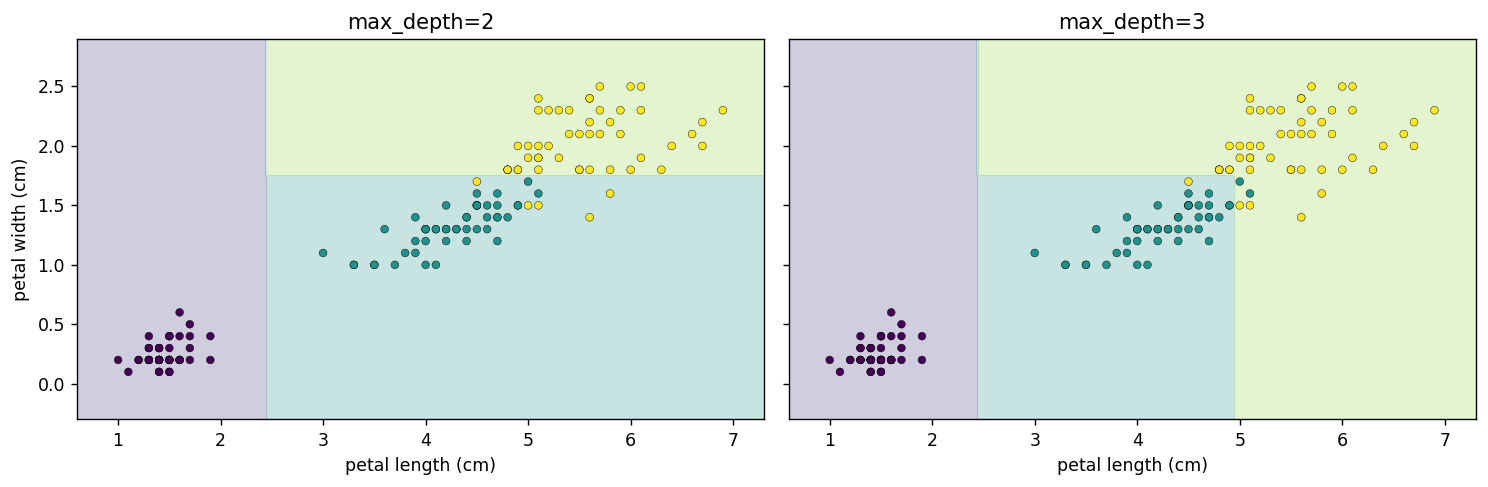

**1단계 확인**

1. 분류 결정 트리의 `gini`와 P2에서 배운 분류 정확도는 어떤 역할이 다른가?
2. 두 자식 노드의 불순도를 계산할 때 왜 샘플 수로 가중평균하는가?
3. 깊이 3 모델에서 추가되는 분할이 **훈련 정확도**와 **일반화 성능**에 미치는 영향은 각각 어떻게 다를 수 있는가?

## 2단계: 트리의 복잡도와 일반화 성능

트리는 데이터의 규칙을 쉽게 학습하지만, 제한 없이 성장하면 작은 훈련 데이터 변화에도 분할 구조가 크게 달라질 수 있다. 이렇게 훈련 데이터에 과도하게 맞추는 현상을 **과대적합**(overfitting)이라고 한다.

P4 실습에서는 잡음이 있는 **초승달 데이터**(moons dataset)에서 깊이를 제한하지 않은 트리와 `min_samples_leaf=5`로 규제한 트리를 비교한다.

### 편향과 분산의 관점

모델이 너무 단순해 중요한 패턴을 놓치는 경우를 **과소적합**(underfitting), 훈련 데이터의 작은 변화나 잡음까지 민감하게 반영하는 경우를 **과대적합**이라고 한다.

- **편향**(bias): 모델이 실제 관계를 지나치게 단순하게 가정하여 놓치는 부분과 관련된다.
- **분산**(variance): 훈련 데이터가 조금 바뀌었을 때 예측이 얼마나 민감하게 바뀌는지와 관련된다.

복잡한 트리는 훈련 데이터에 매우 잘 맞을 수 있지만, 분산이 커져 새 데이터에서 불안정할 수 있다. 반대로 트리를 지나치게 단순하게 제한하면 편향이 커져 중요한 관계를 놓칠 수 있다.

### `max_depth`와 `min_samples_leaf`로 규제하기

트리의 성장 정도를 조절하는 대표적인 **규제 하이퍼파라미터**(regularization hyperparameter)는 다음과 같다.

| 하이퍼파라미터 | 의미 | 과대적합을 억제하려면 |
|---|---|---|
| `max_depth` | 허용할 최대 깊이 | 더 작게 제한 |
| `min_samples_leaf` | 각 잎이 가져야 할 최소 샘플 수 | 더 크게 설정 |
| `min_samples_split` | 노드를 나눌 때 필요한 최소 샘플 수 | 더 크게 설정 |

P4 실습에서는 `min_samples_leaf=5`로 각 잎에 최소 다섯 개의 훈련 샘플이 남도록 제한한다. 이 경우 아주 작은 영역을 따로 나누는 분할이 줄어들 수 있다.

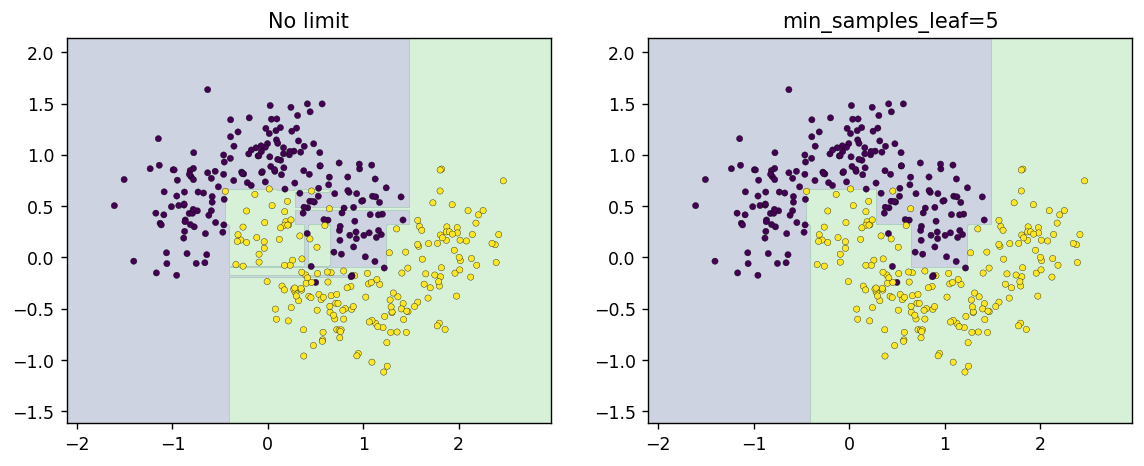

### 훈련 정확도와 테스트 정확도를 함께 읽기

규제를 하지 않은 트리의 결정 경계는 훈련 데이터의 작은 굴곡까지 따라갈 수 있다. 규제한 트리는 경계가 더 단순해질 수 있다.

중요한 것은 **훈련 정확도가 가장 높은 모델을 선택하는 것이 아니라, 새로운 데이터에서 성능이 잘 유지되는 모델을 찾는 것**이다.

실습의 두 모델 비교는 구조의 차이를 관찰하기 위한 예시다. 실제 하이퍼파라미터 선택에서는 **훈련 데이터 내부의 검증셋이나 교차 검증**을 활용하고, 테스트셋은 마지막 평가에 사용해야 한다.

### 교차 검증으로 트리 복잡도 선택하기

실습에서는 다음 후보들을 `GridSearchCV`로 비교한다.

- `max_depth`: `2`, `3`, `4`, `6`, `None`
- `min_samples_leaf`: `1`, `3`, `5`, `10`
- `cv=5`: 훈련셋 안에서 5겹 교차 검증

이것은 **모델 파라미터를 직접 학습하는 과정**이 아니라, **하이퍼파라미터 조합을 비교하여 선택하는 과정**이다.

> **훈련셋 내부의 교차 검증으로 설정 선택 → 선택한 모델을 훈련 → 보관한 테스트셋에서 최종 평가**

이 원칙은 P1의 회귀 모델 비교와 P2의 분류 모델 튜닝에서도 사용했다.

**2단계 확인**

1. `min_samples_leaf`를 늘리면 분할이 왜 제한될 수 있는가?
2. 훈련 정확도가 높지만 테스트 정확도가 낮다면 어떤 문제를 의심해야 하는가?
3. `GridSearchCV`의 `cv=5`가 테스트셋을 다섯 번 사용한다는 뜻인가?

## 3단계: 배깅은 왜 여러 트리를 결합하는가?

**앙상블 학습**(ensemble learning)은 여러 모델의 예측을 결합하여 최종 예측을 만드는 방법이다. 하나의 결정 트리는 훈련 데이터의 변화에 민감할 수 있으므로, 서로 다른 훈련 데이터를 본 여러 트리를 결합하면 예측의 변동성이 작아질 수 있다.

P4 실습은 같은 초승달 데이터에서 단일 트리와 `BaggingClassifier`를 비교한다.

### 부트스트랩: 같은 크기로 뽑아도 같은 데이터는 아니다

**배깅**(bagging)은 *bootstrap aggregating*의 줄임말이다. 여러 모델을 학습할 때 **부트스트랩**(bootstrap), 즉 훈련 샘플을 **복원추출**해 각 모델의 훈련 데이터를 구성한다.

복원추출은 한 샘플을 뽑은 뒤 다시 추출 대상에 넣는 방법이다. 따라서 **같은 샘플이 여러 번 뽑힐 수 있고, 전혀 뽑히지 않는 샘플도 존재**한다.

- `n_estimators=100`: 기본 예측기 100개를 학습한다.
- `max_samples=0.8`: 각 트리에서 훈련 샘플 수의 80%에 해당하는 개수를 추출한다.
- `bootstrap=True`: 이 샘플들을 복원추출한다.
- `max_features=1.0`: 각 트리에서 모든 입력 특성을 사용할 수 있다.

실습의 `BaggingClassifier`는 이 설정으로 트리들을 훈련한다. `max_samples=1.0`이라고 해도 **서로 다른 샘플을 100% 한 번씩 사용한다는 뜻은 아니다.**

<div align="center">
    <img src="https://codingalzi.github.io/code-workout-ml/build/4594ad1dc0a5f9f5861f346e38739849.png" width="500">
</div>

위 그림에서 **선택된 샘플은 중복될 수 있고**, 선택되지 않은 샘플은 그 트리에 대한 OOB가 된다. 부트스트랩은 새로운 데이터를 만들어내는 것이 아니라, **기존 훈련 데이터에서 서로 다른 표본을 구성하는 방법**이다.

### 예측은 어떻게 결합할까?

각 트리는 독립적인 부트스트랩 데이터로 학습하고, 새 샘플에 대한 예측을 만든다. 분류에서는 여러 트리가 만든 예측을 종합하여 최종 클래스를 결정한다.

직관적으로는 **여러 트리의 투표**라고 이해할 수 있다. 다만 scikit-learn의 `BaggingClassifier`는 기본 추정기가 `predict_proba()`를 지원하면 **클래스별 예측 확률을 평균하여** 최종 클래스를 선택한다. 지원하지 않는 경우에는 예측 클래스의 투표를 이용한다.

독립적으로 학습한 여러 트리를 결합하면 한 트리의 우연한 분할에 덜 의존할 수 있다. 그러나 트리들이 거의 같은 오류를 반복하면 앙상블 효과가 제한될 수 있다.

### OOB 샘플로 성능을 살펴보기

어떤 트리의 부트스트랩 데이터에 **선택되지 않은 훈련 샘플**을 그 트리에 대한 **OOB 샘플**(out-of-bag sample)이라고 한다.

하나의 샘플이 어떤 트리에서는 훈련에 사용되고, 다른 트리에서는 OOB가 될 수 있다. 따라서 **OOB는 모델 전체의 훈련셋과 분리한 별도 데이터셋을 뜻하지 않는다.**

OOB 평가에서는 해당 샘플을 훈련에 사용하지 않은 트리들의 예측을 모아 성능을 추정한다. 실습의 `oob_score=True`는 이런 방식으로 분류 정확도를 계산한다.

OOB 정확도는 유용한 **내부 검증 신호**이지만, 최종 테스트셋의 독립적인 평가를 자동으로 대신하지는 않는다.

**OOB는 평균적으로 몇 %일까?**

원본 훈련 샘플 수가 $n$이고 한 트리를 위해 $k$번 복원추출하면, **특정 원본 샘플이 한 번도 선택되지 않을 확률**은 다음과 같다.

$$ P(\mathrm{OOB})=\left(1-\frac{1}{n}\right)^k \approx e^{-k/n} $$

- **일반적인 부트스트랩**: $k=n$이면 OOB가 약 **36.8%**, 적어도 한 번 뽑힌 원본 샘플이 약 **63.2%**다.
- **이번 P4 실습**: `max_samples=0.8`이므로 $k\approx 0.8n$이다. 따라서 한 트리에 대해 OOB가 약 **44.9%**($e^{-0.8}$), 적어도 한 번 뽑힌 원본 샘플은 약 **55.1%**다.

여기서 비율은 **트리 한 개의 부트스트랩 표본에 대한 평균적인 비율**이다. 전체 앙상블에서 '훈련 데이터의 44.9%를 별도 테스트셋으로 떼어 둔다'는 뜻이 아니다. OOB로 남는 샘플은 트리마다 달라진다.

### 배깅에서도 특성 일부만 사용할 수 있다

`BaggingClassifier`의 기본값 `max_features=1.0`은 각 트리가 **모든 특성**을 사용할 수 있다는 뜻이다. 그러나 `max_features=0.7`처럼 지정하면 각 트리별로 **전체 특성의 일부를 미리 선택**할 수 있다.

`bootstrap_features=False`가 기본값이므로 특성은 중복 없이 선택된다. 이것은 **각 트리의 훈련 시작에 사용할 특성을 선택하는 방식**이라는 점을 기억하자. 다음 단계의 랜덤 포레스트는 특성을 선택하는 시점이 다르다.

**3단계 확인**

1. 같은 훈련셋에서 부트스트랩으로 뽑은 두 샘플 묶음이 달라질 수 있는 이유는 무엇인가?
2. `BaggingClassifier(max_samples=0.8, max_features=1.0)`은 샘플과 특성을 각각 어떻게 사용하나?
3. OOB 평가가 별도의 최종 테스트셋 평가와 다른 이유는 무엇인가?

## 4단계: 랜덤 포레스트는 배깅과 무엇이 다른가?

**랜덤 포레스트**(random forest)는 여러 결정 트리를 결합하는 앙상블 모델이다. 부트스트랩 샘플을 사용한다는 점에서 배깅과 닮았지만, 기본적으로 **각 분할 노드에서 후보 특성 일부를 무작위로 선택**한다는 특징이 있다.

이렇게 하면 트리들이 항상 같은 강력한 특성으로만 분할하는 현상을 줄일 수 있어, 여러 트리의 예측이 지나치게 비슷해지는 것을 완화할 수 있다.

<div align="center">
    <img src="https://codingalzi.github.io/code-workout-ml/build/9e798d8b48e0e7de0d8bc80f74d7255d.png" width="550">
</div>

여러 트리는 서로 다른 부트스트랩 표본과 **노드별 무작위 분할 후보 특성**을 바탕으로 학습된다. 분류에서는 예측 확률을 종합하고, 회귀에서는 예측값을 평균한다.

### 배깅의 특성 선택과 랜덤 포레스트의 특성 선택

| 비교 | `BaggingClassifier` | `RandomForestClassifier` |
|---|---|---|
| 기본 예측기 | 지정한 분류기(실습: 결정 트리) | 결정 트리 |
| 샘플 선택 | 보통 부트스트랩 | 기본적으로 부트스트랩 |
| 특성 선택 시점 | 모델마다 사용할 특성을 처음에 선택 가능 | **각 노드의 분할마다** 후보 특성을 선택 |
| 예 | `max_features=0.7`이면 트리별 약 70% 선택 | `max_features="sqrt"`이면 노드마다 약 $\sqrt{p}$개 후보 |

여기서 $p$는 전체 특성 수다. **랜덤 포레스트가 트리 전체에서 일부 특성만 사용할 수 있다는 뜻은 아니다.** 서로 다른 노드에서는 서로 다른 특성이 후보가 될 수 있다.

실습의 초승달 분류에서는 `RandomForestClassifier(n_estimators=200, max_features="sqrt")`를 사용한다.

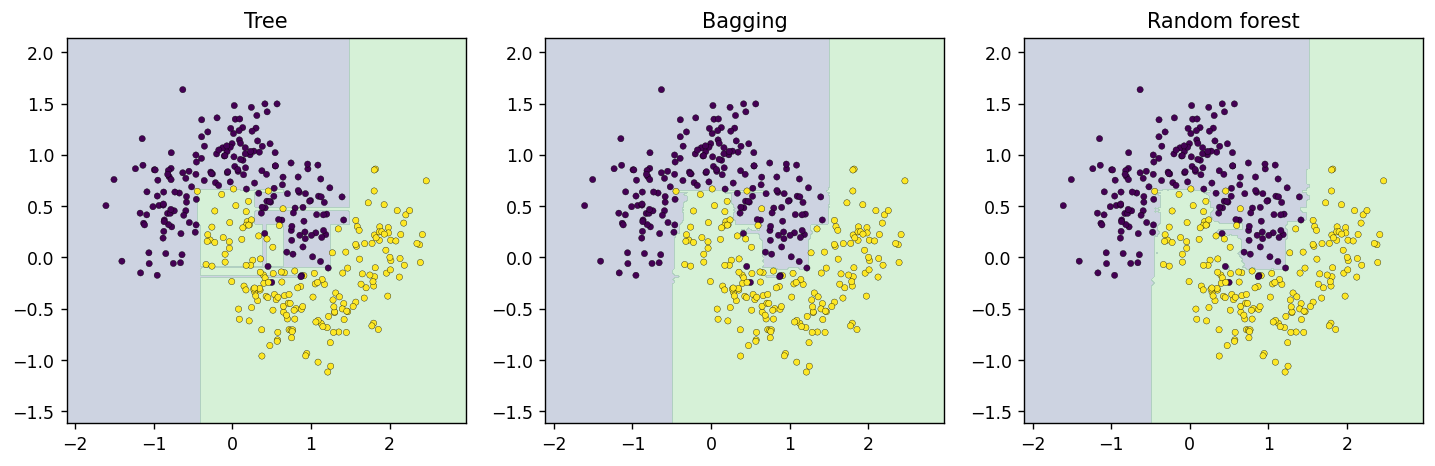

위 그림은 P4 실습의 같은 훈련셋으로 학습한 세 모델의 결정 경계다. 단일 트리와 앙상블의 경계 형태가 다르다는 것을 확인하되, **경계가 매끄러워 보인다는 이유만으로 테스트 성능이 항상 좋다고 판단하지는 말자.** 실제 평가 지표와 데이터 분할의 타당성을 함께 확인해야 한다.

### 랜덤 포레스트는 분류와 회귀 모두 가능하다

랜덤 포레스트의 핵심은 여러 트리의 예측을 결합한다는 점이며, 이 원리는 **분류**와 **회귀**에 모두 적용된다.

- **분류**(`RandomForestClassifier`): 여러 분류 트리의 클래스별 예측 확률을 평균하고 가장 높은 확률의 클래스를 선택한다.
- **회귀**(`RandomForestRegressor`): 여러 회귀 트리가 예측한 숫자값을 **산술평균**한다.

회귀에서는 각 트리의 예측값을 $\hat y_1,\ldots,\hat y_B$라 하면 최종 예측은 다음과 같다.

$$ \hat y_{\mathrm{forest}} = \frac{1}{B}\sum_{b=1}^{B}\hat y_b $$

트리별 예측값이 모두 같지는 않더라도 평균을 이용하면 한 트리의 극단적인 예측에 대한 의존을 줄일 수 있다.

### 특성 중요도는 무엇을 말해 줄까?

랜덤 포레스트의 `feature_importances_`는 각 특성이 트리 분할 과정에서 **불순도를 얼마나 줄였는지**를 종합한 값이다. 값이 클수록 그 모델에서 분할에 많이 기여했다는 의미다.

하지만 다음을 구별해야 한다.

- **말할 수 있는 것:** 이 모델과 이 데이터에서 특정 특성이 분할에 상대적으로 크게 기여했다.
- **말할 수 없는 것:** 이 특성이 결과를 *인과적으로* 변화시켰다, 다른 데이터에서도 반드시 중요하다, 또는 이 특성만으로 예측이 결정된다.

불순도 기반 중요도는 특성의 값 종류가 많거나 서로 상관된 특성이 있을 때 해석에 주의해야 한다. P1~P3에서 배운 것처럼 중요도 역시 **데이터와 분석 목적을 함께 고려**해야 한다.

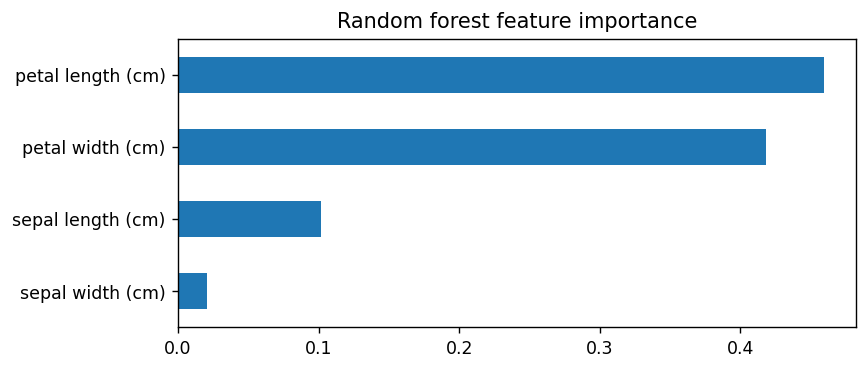

### 단일 회귀 트리와 랜덤 포레스트 회귀 비교

P4 실습에서는 곡선 형태의 데이터를 훈련셋과 검증셋으로 나누고 `DecisionTreeRegressor`와 `RandomForestRegressor(n_estimators=100)`를 비교한다.

실습 설정에서 산출되는 대표적인 RMSE는 다음과 같다(라이브러리 버전에 따라 작은 차이가 있을 수 있다).

| 모델 | 훈련 RMSE | 검증 RMSE |
|---|---:|---:|
| 단일 회귀 트리 | 0.000 | 0.145 |
| 랜덤 포레스트 회귀 | 0.045 | 0.122 |

단일 트리는 훈련 데이터를 매우 잘 맞추지만 검증셋에서 오차가 커질 수 있다. 반면 여러 트리를 평균한 랜덤 포레스트는 이 예제에서 검증 오차가 더 작게 나타난다. **하지만 랜덤 포레스트가 모든 데이터에서 항상 우수하다는 결론은 아니다.**

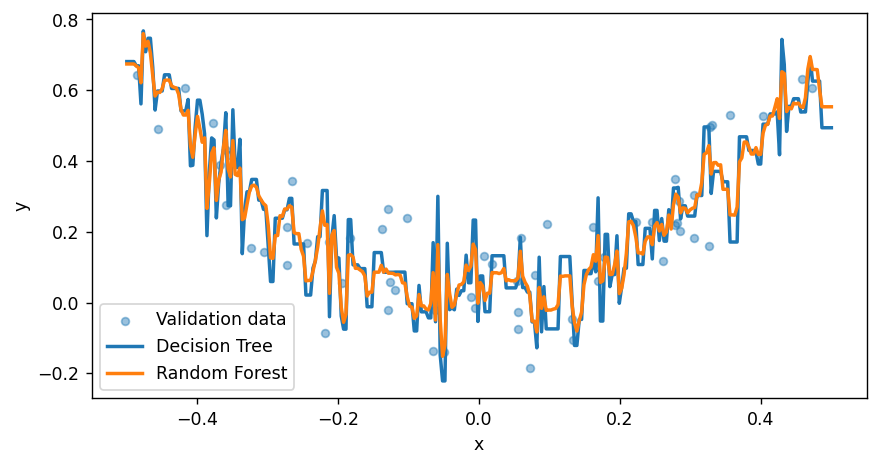

### 회귀 결정 트리는 무엇을 기준으로 분할하는가?

분류 트리가 지니 불순도를 줄이도록 나뉘었다면, 회귀 트리는 한 잎 안의 **타깃값 차이**를 줄이도록 나뉜다. 기본 회귀 트리에서는 각 잎에 속한 훈련 샘플의 **타깃 평균**을 그 잎의 예측값으로 사용한다.

잎에 들어 있는 샘플들이 같은 예측값을 받으므로 회귀 트리의 예측 곡선은 보통 **계단 형태**다.

분할 기준을 정할 때는 자식 노드들의 제곱 오차를 샘플 수로 가중하여 작게 만드는 분할을 찾는다.

$$ J = \frac{m_{\mathrm{left}}}{m}\mathrm{MSE}_{\mathrm{left}} + \frac{m_{\mathrm{right}}}{m}\mathrm{MSE}_{\mathrm{right}} $$

여기서 $\mathrm{MSE}_{\mathrm{left}}$와 $\mathrm{MSE}_{\mathrm{right}}$는 각각 해당 자식 노드 안에서의 평균 제곱 오차다. P3에서 배운 MSE가 **여기서는 트리의 분할 품질을 판단하는 기준**으로 연결된다.

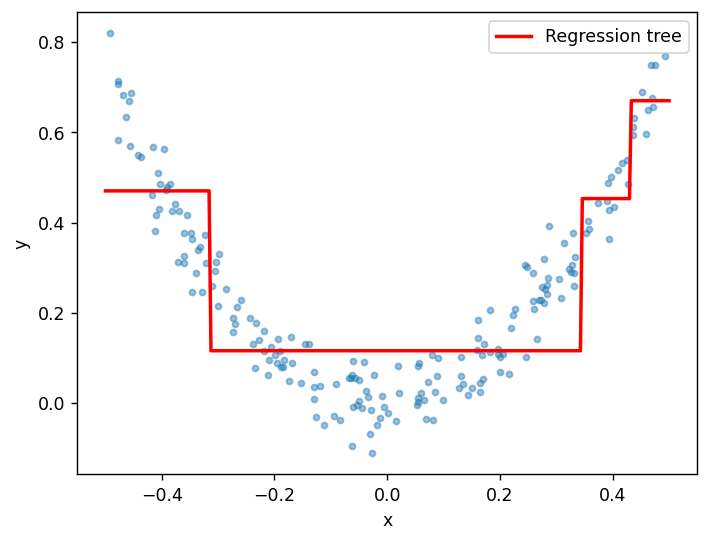

**4단계 확인**

1. `BaggingClassifier(max_features=0.7)`과 `RandomForestClassifier(max_features="sqrt")`는 언제 특성을 선택하는가?
2. 랜덤 포레스트 회귀의 최종 예측값을 여러 트리의 평균이라고 설명하는 이유는 무엇인가?
3. `feature_importances_`가 높다는 사실이 그 특성의 인과적 영향력을 증명하는가?

## 5단계: 그레이디언트 부스팅은 왜 순서대로 학습하는가?

**부스팅**(boosting)은 앞에서 만든 모델의 부족한 부분을 보완하도록 새 모델을 **순차적으로 추가**하는 앙상블 학습 방법이다.

배깅과 랜덤 포레스트는 여러 트리를 각자의 부트스트랩 데이터로 학습하고 예측을 합친다. 반면 **그레이디언트 부스팅**(gradient boosting)은 앞 단계까지의 예측이 만든 손실을 줄이는 방향으로 다음 트리를 학습한다.

여기서 중요한 것은 **기존 트리 하나의 파라미터를 계속 수정하는 것이 아니라, 보완하는 새 트리를 더해 전체 모델의 예측을 바꾸는 것**이다.

### 회귀 부스팅: 첫 트리의 잔차를 두 번째 트리가 학습한다

회귀 문제에서 **제곱 오차**를 손실로 사용한다면, 다음 모델이 학습해야 할 방향을 **잔차**(residual)와 연결해서 이해할 수 있다.

$$ r_i = y_i - \hat y_i $$

잔차는 실제값에서 현재 예측값을 뺀 값이다.

- 첫 번째 트리가 $\hat y_1(x)$를 예측한다.
- 두 번째 트리는 첫 번째 트리가 남긴 $y-\hat y_1$을 학습한다.
- 세 번째 트리는 첫 두 트리의 예측을 합한 후에도 남은 잔차를 학습한다.

P4 실습은 깊이 2인 회귀 트리 세 개를 차례대로 학습하고 결과를 합한다. 이 수동 예제에서는 새 트리의 예측을 가중치 `1`로 더한다.

$$ \hat y_{\mathrm{total}}(x) = \hat y_1(x) + \hat r_2(x) + \hat r_3(x) $$

같은 훈련 데이터에서 실습의 MSE는 **트리 1개일 때 약 0.0127, 세 트리를 합했을 때 약 0.0043**으로 계산된다. 이것은 **훈련 MSE**의 변화이며, 검증·테스트 성능이 반드시 개선됐다는 뜻은 아니다.

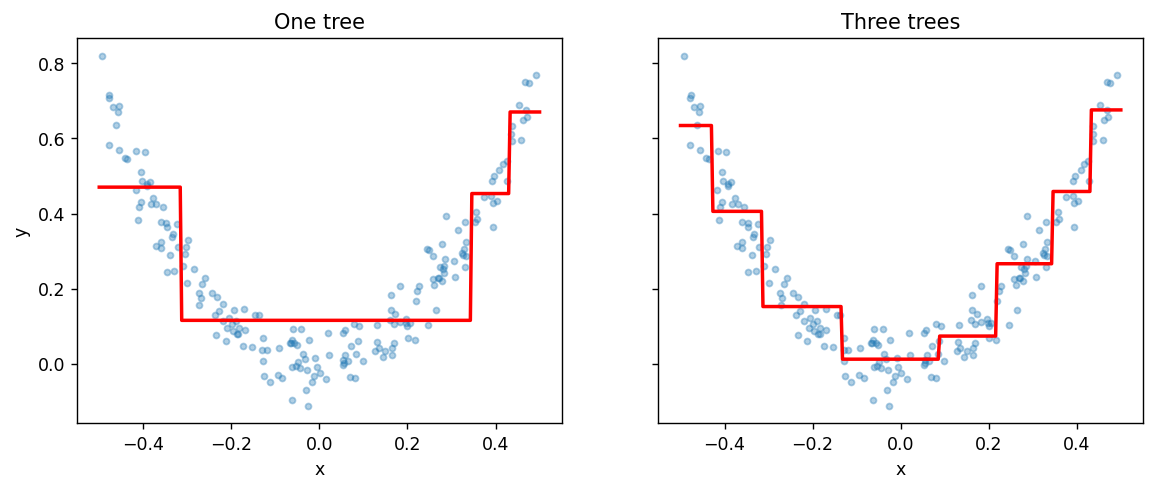

### 왜 이름에 gradient가 들어갈까?

그레이디언트 부스팅은 **현재 모델의 예측을 보정하는 새로운 결정 트리를 반복적으로 추가**한다.

예를 들어 실제값이 10인데 현재 모델의 예측값이 7이라면, 잔차는 \(10-7=3\)이다. 새 트리는 이러한 잔차를 예측하도록 학습하며, 기존 모델의 예측에 새 트리의 예측을 더하면 실제값에 가까워질 수 있다.

그런데 왜 잔차를 학습하는 방법을 **그레이디언트 부스팅**이라고 부를까?

제곱 오차 손실 함수를 다음과 같이 정의하자.

$$
L=\frac12(y-\hat y)^2
$$

이 손실 함수를 **예측값 \(\hat y\)** 에 대해 미분하면 다음과 같다.

$$
\frac{\partial L}{\partial \hat y}=\hat y-y
$$

따라서 손실을 줄이는 방향인 **음의 기울기**는 다음과 같다.

$$
-\frac{\partial L}{\partial \hat y}=y-\hat y
$$

즉, **제곱 오차에서는 음의 기울기가 바로 잔차이다.** 따라서 새로운 트리가 잔차를 예측하도록 학습하는 것은 손실을 줄이는 방향을 학습하는 것과 같다.

새로운 트리를 추가하는 과정은 다음과 같이 나타낼 수 있다.

$$
F_m(x)=F_{m-1}(x)+\eta h_m(x)
$$

- $F_{m-1}(x)$
: 기존 모델의 예측
- $h_m(x)$: 음의 기울기를 근사하도록 학습한 새로운 트리
- $\eta$: 새 트리의 예측을 얼마나 반영할지 결정하는 학습률

**P3의 경사하강법**은 기울기를 이용해 기존 모델의 파라미터를 수정한다. 반면 **P4의 그레이디언트 부스팅**은 기울기를 이용해 새로운 트리를 학습하고 기존 모델에 추가한다.

분류처럼 손실 함수가 제곱 오차가 아닌 경우에는 음의 기울기가 단순한 잔차 \(y-\hat y\)와 같지 않을 수 있다. 하지만 **손실의 음의 기울기를 이용해 새 모델을 학습한다**는 기본 원리는 같다.

### 부스팅의 학습률은 P3의 학습률과 무엇이 다를까?

실습의 `GradientBoostingRegressor`는 `n_estimators=100`, `max_depth=2`, `learning_rate=0.1`을 사용한다.

부스팅에서 **학습률**(learning rate)은 새로 학습한 트리가 전체 예측에 **얼마나 크게 기여하는지**를 조절한다. 이를 간단히 쓰면

$$ F_m(x) = F_{m-1}(x) + \eta\,h_m(x) $$

- $F_{m-1}(x)$: 이전 단계까지 결합한 모델의 예측
- $h_m(x)$: 새로 추가하는 트리가 예측하는 보완값
- $\eta$: 부스팅의 학습률

`learning_rate`를 작게 하면 **한 트리가 추가하는 변화가 작아진다.** 그래서 비슷한 수준까지 학습하려면 더 많은 트리가 필요할 수 있다. 반대로 학습률이나 트리 수를 크게 하면 과대적합의 위험도 있으므로 검증을 통해 선택한다.

**P3에서는 gradient를 곱해 파라미터를 직접 수정했고, P4에서는 새 트리의 기여도를 조절한다는 차이**를 기억하자.

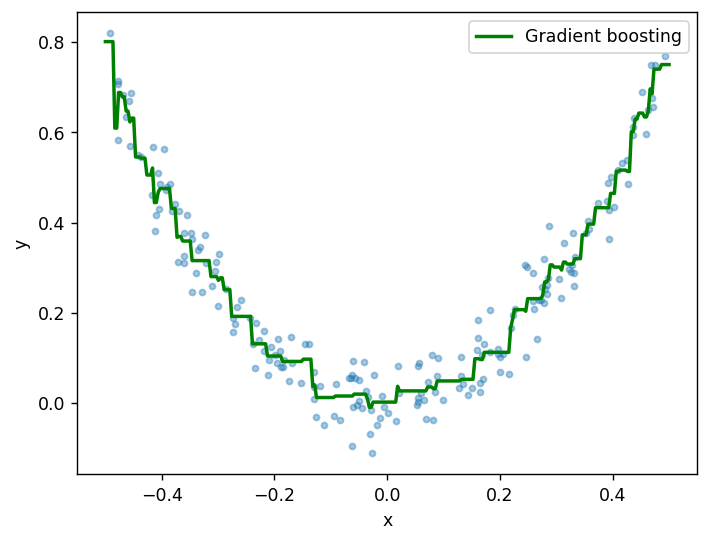

### 트리 개수가 많으면 항상 좋은가?

P4 실습은 `n_estimators`가 `1`, `5`, `20`, `100`인 그레이디언트 부스팅 회귀 모델의 **훈련 MSE**를 비교한다. 모델이 추가될수록 훈련 손실이 작아지는 결과를 볼 수 있다.

하지만 모델 선택의 목표는 훈련 손실을 가능한 한 작게 만드는 것만이 아니다.

> **훈련 성능 개선 ≠ 새로운 데이터에서의 성능 개선 보장**

`n_estimators`, `max_depth`, `learning_rate`는 **하이퍼파라미터**이며, P1처럼 검증셋이나 교차 검증을 이용해 선택해야 한다. 테스트셋은 최종 일반화 성능 평가를 위해 보관한다.

### 부스팅 분류: 로그 손실을 줄이는 방향으로

그레이디언트 부스팅은 **분류에도 적용**된다. P4 실습에서는 `GradientBoostingClassifier`와 `RandomForestClassifier`를 같은 초승달 데이터에서 비교한다.

P2에서 **로지스틱 회귀**는 예측 확률에 관한 **로그 손실**(log loss)을 작게 만드는 모델 파라미터를 찾는다고 배웠다. **그레이디언트 부스팅 분류** 역시 분류 손실을 줄이도록 새로운 트리를 더한다.

이진 분류의 로그 손실은 다음과 같다.

$$ L(y,\hat p)=-[y\log(\hat p)+(1-y)\log(1-\hat p)] $$

분류 부스팅에서는 예측 확률과 연결된 **점수**를 업데이트하며 이 손실을 줄이는 방향을 학습한다. 따라서 **회귀 예제처럼 숫자 잔차 $y-\hat y$를 직접 다음 트리의 타깃으로 삼는 방식과 동일하다고 생각하면 안 된다.**

핵심은 회귀와 분류 모두 **현재 전체 모델의 손실을 줄이도록 새 트리를 순차적으로 추가한다**는 것이다.

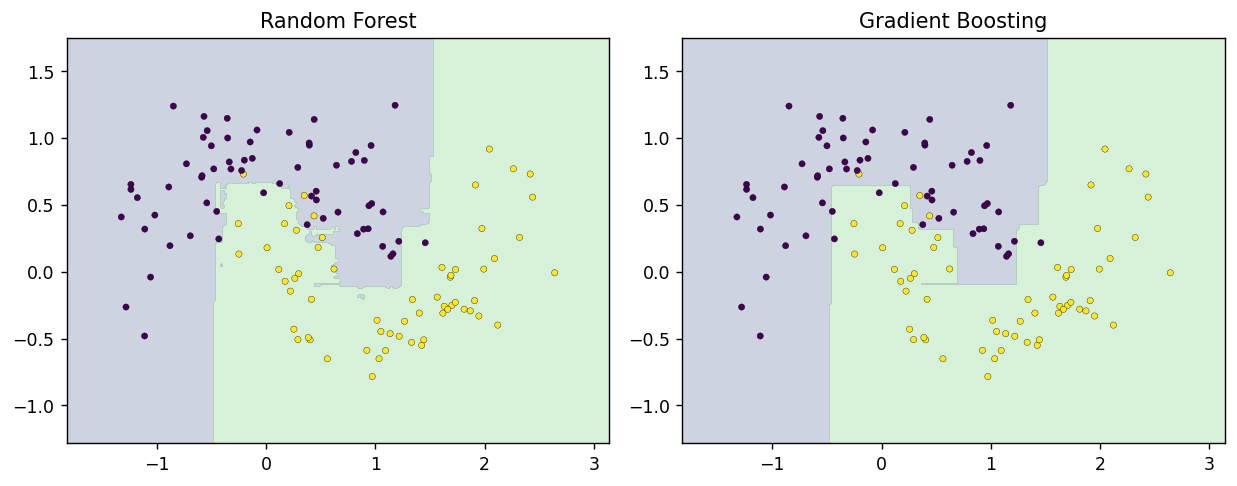

### XGBoost: 그레이디언트 부스팅의 또 다른 구현

**XGBoost**(Extreme Gradient Boosting)는 **부스팅 계열의 트리 모델**을 효율적으로 학습하도록 만든 라이브러리다. 앞에서 배운 그레이디언트 부스팅처럼 **새로운 트리를 순차적으로 추가하여 손실을 줄이는 방식**을 사용한다. 단, scikit-learn의 `GradientBoostingClassifier`와 내부 구현이 완전히 같은 모델은 아니다.

XGBoost는 트리의 복잡도를 제한하는 **규제**(regularization), 효율적인 트리 학습, 샘플·특성 일부 선택 등 다양한 기능을 제공한다. 손실 함수의 변화 정보(일차·이차 미분)를 활용한다는 점도 특징이지만, 여기서는 수학적 유도보다 **기존 부스팅 모델과 같은 목적을 다른 구현으로 달성한다**는 점에 집중한다.

| 문제 | XGBoost 모델 | 대표 손실·목적 |
|---|---|---|
| 이진 분류 | `XGBClassifier` | 로그 손실을 줄이는 방향의 학습 |
| 회귀 | `XGBRegressor` | 제곱 오차 등을 줄이는 방향의 학습 |

| 주요 설정 | 의미 |
|---|---|
| `n_estimators` | 순차적으로 추가할 트리의 수 |
| `learning_rate` | 새로 추가하는 트리의 기여도 |
| `max_depth` | 각 트리의 최대 깊이 |
| `subsample` | 트리 학습에 사용할 훈련 샘플의 비율 |
| `colsample_bytree` | 트리별 사용할 특성의 비율 |
| `reg_lambda` | 잎 가중치에 대한 L2 규제 강도 |

P4 실습에서는 **같은 초승달 데이터**에서 `RandomForestClassifier`, `GradientBoostingClassifier`, `XGBClassifier`를 비교하고, **같은 곡선형 회귀 데이터**에서 `XGBRegressor`도 짧게 실행한다. `xgboost`는 scikit-learn과 별도로 설치해야 한다.

> XGBoost가 항상 더 정확한 것은 아니다. 성능을 비교할 때는 같은 데이터 분할과 평가 지표를 사용하고, 하이퍼파라미터를 조정할 때는 검증셋이나 교차 검증을 사용한다.

참고: [XGBoost 공식 Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html)

### 랜덤 포레스트와 부스팅 중 무엇을 선택할까?

실습에서 동일한 초승달 데이터에서 `RandomForestClassifier`와 `GradientBoostingClassifier`의 훈련 정확도·테스트 정확도를 비교한다. 해당 실행 설정에서는 두 모델의 테스트 정확도가 모두 약 `0.944`로 나타났다.

그러나 이 결과만으로 **두 모델이 언제나 같은 성능을 낸다**거나 **특정 모델이 언제나 우수하다**고 결론 내릴 수 없다. 데이터, 전처리, 손실·평가 지표, 하이퍼파라미터가 바뀌면 결과도 달라진다.

검증 성능의 차이가 작다면 모델의 복잡도, 실행 시간, 해석 가능성 등을 함께 고려할 수도 있다. 프로젝트에서는 어떤 모델을 골랐는지보다 **어떤 근거로 선택했는지**가 중요하다.

**5단계 확인**

1. 회귀 부스팅에서 두 번째 트리가 첫 번째 트리와 같은 타깃을 그대로 학습하지 않는 이유는 무엇인가?
2. P3의 경사하강법과 P4의 그레이디언트 부스팅에서 `learning_rate`가 각각 무엇을 조절하는가?
3. 분류 부스팅의 손실을 줄이는 과정을 회귀의 숫자 잔차 합산과 완전히 동일하게 설명해도 되는가?
4. 부스팅의 훈련 MSE가 더 작아졌더라도 검증을 해야 하는 이유는 무엇인가?

## 6단계: 세 가지 방법을 어떻게 비교하고 판단할까?

| 방식 | 학습의 핵심 | 예측 결합 | 주의할 점 |
|---|---|---|---|
| **결정 트리** | 각 노드에서 좋은 분할을 선택 | 잎에서 예측 | 깊이 증가와 과대적합 |
| **배깅** | 부트스트랩으로 서로 다른 훈련 샘플 구성 | 여러 모델의 예측 결합 | 모델 다양성, OOB 해석 |
| **랜덤 포레스트** | 부트스트랩 + 노드별 후보 특성 무작위 선택 | 분류는 확률 평균, 회귀는 숫자 평균 | 중요도 해석, 하이퍼파라미터 |
| **그레이디언트 부스팅** | 이전 전체 예측의 손실을 줄이도록 순차적 트리 추가 | 새 트리의 보완 예측을 누적 | 학습률·트리 수·과대적합 |

모든 모델은 회귀·분류에 활용할 수 있지만, **손실 함수, 예측 결합 방식, 출력의 의미**는 문제에 따라 달라진다.

### 앙상블 학습 방식 비교

![앙상블 학습의 모델 결합 예시](https://drek4537l1klr.cloudfront.net/kunapuli/Figures/CH01_F02_Kunapuli.png)

<small>참고 그림: Gautam Kunapuli, *Ensemble Methods for Machine Learning* (Manning), [원본 이미지](https://drek4537l1klr.cloudfront.net/kunapuli/Figures/CH01_F02_Kunapuli.png). 인터넷 연결 시 표시된다.</small>

그림을 참고해 **여러 모델을 각각 학습해 결합하는 방식**과 **앞 모델의 부족한 부분을 다음 모델이 보완하는 방식**을 구별하자. 다음 표는 P4 실습에서 다룬 모델의 공통점과 차이를 정리한다.

| 모델 | 트리의 학습 방법 | 최종 예측 | 특히 확인할 점 |
|---|---|---|---|
| 단일 결정 트리 | 트리 하나를 학습 | 잎의 예측을 사용 | 구조 해석, 깊이와 과대적합 |
| 배깅 | 부트스트랩 표본으로 여러 트리를 독립적으로 학습 | 확률 평균·투표 등 | 샘플 다양성, OOB |
| 랜덤 포레스트 | 부트스트랩 + 노드별 무작위 특성 선택 | 분류 확률 평균 / 회귀 예측값 평균 | 트리 간 다양성, 특성 중요도 |
| 그레이디언트 부스팅 | 이전 모델의 손실을 줄이도록 트리를 **순차적으로** 추가 | 트리들의 보정 기여를 합산 | 학습률, 트리 수, 과대적합 |
| XGBoost | 규제 등을 포함한 트리 부스팅을 **순차적으로** 학습 | 순차적 트리 보정값을 종합 | 트리 복잡도, 규제, 검증 성능 |

**중요:** 실제 모델 선택은 알고리즘 이름만으로 결정하지 않는다. 동일한 분할·지표 아래의 **검증 성능과 오류 패턴**을 근거로 판단한다.

### P1~P3에서 배운 원칙을 다시 적용하기

- **P1 — 일반화와 모델 선택:** 학습용 데이터와 최종 평가용 데이터를 구분한다. 하이퍼파라미터는 훈련셋 내부 검증 또는 교차 검증으로 선택한다.
- **P2 — 분류의 평가:** 정확도뿐 아니라 데이터 불균형과 오류 비용을 살펴보고, 필요하면 정밀도·재현율 등 적절한 지표로 평가한다.
- **P3 — 손실과 최적화:** 모델 훈련에는 기준이 되는 손실이 있다. 다만 **트리의 분할 학습**과 **경사하강법**, **그레이디언트 부스팅**은 손실을 줄이는 구체적인 방식이 다르다.

P4 실습의 붓꽃·초승달·곡선 데이터를 비교할 때도 같은 원칙을 유지해야 한다. **코드가 실행되고 훈련 성능이 높다고 해서 모델 선택이 정당화되는 것은 아니다.**

## 이론 정리

이번 P4에서 기억할 핵심은 다음과 같다.

- 결정 트리는 특성과 임곗값으로 데이터를 분할하고, 잎 노드에서 예측한다.
- 분류 트리의 기본 지니 불순도는 한 노드에 클래스가 얼마나 섞여 있는지를 나타낸다.
- 깊이가 2인 트리보다 깊이 3인 트리가 세밀한 규칙을 만들 수 있지만, **훈련 정확도 상승이 일반화 성능 상승을 뜻하지는 않는다.**
- `max_depth`, `min_samples_leaf`와 같은 하이퍼파라미터로 트리의 복잡도를 조절할 수 있다.
- 배깅은 샘플을 복원추출해 여러 트리를 학습한다. OOB 샘플은 **해당 트리**의 훈련에 선택되지 않은 샘플이다.
- `BaggingClassifier`의 `max_features`는 기본적으로 **트리별 특성 선택**이며, 랜덤 포레스트의 `max_features`는 **노드별 분할 후보 선택**이다.
- 랜덤 포레스트 분류는 트리별 확률을 결합하고, 랜덤 포레스트 회귀는 예측 숫자를 평균한다.
- 회귀 결정 트리는 잎의 타깃 평균으로 예측하며, 분할할 때는 제곱 오차를 줄인다.
- 부스팅은 새 트리를 순차적으로 더해 이전 예측의 부족한 부분을 보완한다.
- 회귀에서 제곱 오차를 사용할 때는 잔차 학습으로 부스팅을 직관적으로 설명할 수 있지만, **분류에서는 로그 손실을 줄이는 원리로 이해해야 한다.**
- 부스팅의 `learning_rate`는 **새로 추가되는 트리의 기여 크기**를 조절한다.

- 부트스트랩에서 크기 $n$만큼 복원추출하면 평균 OOB는 약 36.8%지만, P4의 `max_samples=0.8`에서는 약 44.9%다.
- XGBoost는 트리를 순차적으로 추가하는 부스팅 모델이며 분류와 회귀 모두에 사용할 수 있다.

> **좋은 모델 선택 = 원리 이해 + 검증 성능 확인 + 분석 목적에 맞는 판단**

## 이해 확인

다음 질문에 자신의 말로 답해 보자.

1. 결정 트리가 지니 불순도를 줄이는 것과 분류 정확도를 높게 평가받는 것은 어떻게 다른가?
2. 깊이 2와 깊이 3 트리에서 잎 노드 수가 달라진 이유는 무엇인가?
3. 규제를 하지 않은 트리의 훈련 정확도가 높은데 테스트 정확도가 떨어지는 이유를 설명해 보자.
4. 배깅에서 `max_samples=1.0`이어도 일부 훈련 샘플이 선택되지 않을 수 있는 이유는 무엇인가?
5. 배깅의 트리별 특성 선택과 랜덤 포레스트의 노드별 특성 선택은 어떻게 다른가?
6. OOB 정확도를 최종 테스트 정확도와 구분해야 하는 이유는 무엇인가?
7. 랜덤 포레스트 회귀가 트리들의 예측을 평균하는 원리는 무엇인가?
8. `feature_importances_`만으로 어떤 특성의 인과적 영향을 주장할 수 없는 이유는 무엇인가?
9. P4의 회귀 부스팅에서 잔차와 P2의 분류 로그 손실은 어떤 관계로 이해해야 하는가?
10. P3의 `learning_rate`와 P4의 부스팅 `learning_rate`는 각각 어떤 값에 영향을 주는가?
11. 훈련 MSE만 비교해 가장 좋은 부스팅 모델을 선택하면 어떤 문제가 있는가?
12. P4 프로젝트에서 결정 트리, 랜덤 포레스트, 부스팅 모델을 비교한다면 어떤 검증 절차와 근거가 필요한가?
13. 깊이 2인 붓꽃 트리의 가장 오른쪽 잎(versicolor 1개, virginica 45개)의 지니 불순도를 계산해 보자.
14. `max_samples=1.0`과 `max_samples=0.8`의 OOB 비율은 어떻게 달라지는가?
15. `XGBClassifier`와 `XGBRegressor`는 각각 어떤 문제에 사용하는가?